# CyberMind — 4 modelos: evaluación con entrenamiento (75 %) y con prueba (25 %)

Este notebook reúne en un solo archivo los cuatro scripts de la carpeta `entreno_vs_prueba/`:

| # | Script | Modelo |
|---|---|---|
| 1 | `01_arbol_decision.py` | Árbol de decisión (CART) |
| 2 | `02_regresion_logistica.py` | Regresión logística |
| 3 | `03_knn.py` | k vecinos más cercanos (kNN) |
| 4 | `04_gbdt.py` | Gradient Boosting de árboles (GBDT) |

**Problema:** clasificación binaria supervisada. Para cada par (estudiante, tema) el modelo decide **REFUERZO** o **AVANCE** a partir del diagnóstico.

**Datos:** solo `cybermind_sintetico.csv` (7 500 filas = 1 500 estudiantes × 5 temas). **No se usa `cybermind_sintetico_oculto.csv`** en ningún paso.

**Partición:** 75 % entrenamiento / 25 % prueba, agrupada por estudiante (un estudiante nunca queda en los dos lados) y con semilla fija, idéntica para los 4 modelos.

**Procedimiento para cada modelo:** (1) entrenar con el 75 %, (2) evaluar con los datos de entrenamiento y mostrar resultados, (3) evaluar con los datos de prueba y mostrar resultados, (4) comparar ambos y graficar.

**Cómo leer la comparación:** la cifra de entrenamiento mide lo bien que el modelo reproduce datos que ya vio; la de prueba, lo bien que generaliza a estudiantes nuevos. Si entrenamiento es mucho mayor que prueba, el modelo está memorizando (sobreajuste). Si ambas son parecidas, lo aprendido se generaliza.

*Métricas:* exactitud (accuracy) = % de decisiones correctas. Precisión, sensibilidad (recall) y F1 se calculan para la clase REFUERZO: precisión = de los enviados a refuerzo, cuántos lo necesitaban; sensibilidad = de los que necesitaban refuerzo, a cuántos se detectó.

## 0. Librerías, datos, partición y funciones comunes

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import GridSearchCV, GroupKFold, GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import GradientBoostingClassifier

%matplotlib inline

In [2]:
# Único archivo de datos: cybermind_sintetico.csv (NO se usa cybermind_sintetico_oculto.csv)
# Se busca en la carpeta actual o en ../data (estructura del repositorio)
RUTA_DATOS = next((c / "cybermind_sintetico.csv" for c in (Path.cwd(), Path.cwd().parent / "data")
                   if (c / "cybermind_sintetico.csv").exists()), None)
if RUTA_DATOS is None:
    raise FileNotFoundError("Coloca cybermind_sintetico.csv junto al notebook o en ../data.")
_REPO = Path.cwd().parent / "pruebas" / "fase2_entreno_vs_prueba" / "resultados"
SALIDA = _REPO if _REPO.parent.is_dir() else Path.cwd() / "resultados"
SALIDA.mkdir(exist_ok=True)
datos = pd.read_csv(RUTA_DATOS)

CATEGORICAS = ["tema", "experiencia_previa"]
NUMERICAS = ["aciertos_basico", "aciertos_intermedio", "aciertos_avanzado", "puntaje_tema",
             "puntaje_global", "tiempo_promedio_seg"]
X = datos[CATEGORICAS + NUMERICAS]
y = (datos["decision"] == "REFUERZO").astype(int)   # clase positiva (1) = REFUERZO, 0 = AVANCE
grupos = datos["id_estudiante"]

# Partición 75 % entrenamiento / 25 % prueba, AGRUPADA por estudiante (un estudiante nunca
# aparece en los dos conjuntos) y con semilla fija: es la misma en los 4 modelos.
ent, pru = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=0).split(X, y, groups=grupos))
X_ent, y_ent, g_ent = X.iloc[ent], y.iloc[ent], grupos.iloc[ent]
X_pru, y_pru = X.iloc[pru], y.iloc[pru]

print(f"Datos: {RUTA_DATOS.name} — {len(datos)} filas, {datos['id_estudiante'].nunique()} estudiantes")
print(f"Entrenamiento: {len(ent)} filas ({len(ent)/len(datos):.0%}), {g_ent.nunique()} estudiantes")
print(f"Prueba:        {len(pru)} filas ({len(pru)/len(datos):.0%}), {grupos.iloc[pru].nunique()} estudiantes")
print("Estudiantes en ambos conjuntos:", len(set(g_ent) & set(grupos.iloc[pru])))
print(f"% REFUERZO — entrenamiento: {y_ent.mean():.1%} | prueba: {y_pru.mean():.1%}")

Datos: cybermind_sintetico.csv — 7500 filas, 1500 estudiantes
Entrenamiento: 5625 filas (75%), 1125 estudiantes
Prueba:        1875 filas (25%), 375 estudiantes
Estudiantes en ambos conjuntos: 0
% REFUERZO — entrenamiento: 64.7% | prueba: 67.6%


In [3]:
COLOR_ENT, COLOR_PRU = "#2a78d6", "#eb6834"   # azul = entrenamiento, naranja = prueba
NOMBRES_METRICAS = {"exactitud": "Exactitud\n(accuracy)", "precision_REFUERZO": "Precisión\n(precision)",
                    "recall_REFUERZO": "Sensibilidad\n(recall)", "F1_REFUERZO": "F1"}


def metricas(y_real, y_pred):
    """Métricas de clasificación; precisión, recall y F1 se calculan para la clase REFUERZO."""
    tn, fp, fn, tp = confusion_matrix(y_real, y_pred, labels=[0, 1]).ravel()
    return {
        "n_filas": int(len(y_real)),
        "exactitud": round(float(accuracy_score(y_real, y_pred)), 4),
        "precision_REFUERZO": round(float(precision_score(y_real, y_pred, zero_division=0)), 4),
        "recall_REFUERZO": round(float(recall_score(y_real, y_pred, zero_division=0)), 4),
        "F1_REFUERZO": round(float(f1_score(y_real, y_pred, zero_division=0)), 4),
        "matriz_confusion": {"VN_avance_ok": int(tn), "FP_refuerzo_innecesario": int(fp),
                             "FN_avance_sin_dominio": int(fn), "VP_refuerzo_ok": int(tp)},
    }


def mostrar(titulo, m):
    """Imprime las métricas de un conjunto en forma de tabla legible."""
    mc = m["matriz_confusion"]
    print(f"\n=== {titulo} — {m['n_filas']} filas ===")
    print(f"  Exactitud (accuracy) ......... {m['exactitud']:.4f}")
    print(f"  Precisión REFUERZO ........... {m['precision_REFUERZO']:.4f}")
    print(f"  Sensibilidad (recall) REFUERZO {m['recall_REFUERZO']:.4f}")
    print(f"  F1 REFUERZO .................. {m['F1_REFUERZO']:.4f}")
    print("  Matriz de confusión (filas = real, columnas = predicho):")
    print(f"                 pred AVANCE  pred REFUERZO")
    print(f"    real AVANCE   {mc['VN_avance_ok']:>9}  {mc['FP_refuerzo_innecesario']:>13}")
    print(f"    real REFUERZO {mc['FN_avance_sin_dominio']:>9}  {mc['VP_refuerzo_ok']:>13}")


def comparar(m_ent, m_pru):
    """Diferencia entrenamiento − prueba en cada métrica (positiva = el modelo rinde mejor en lo que ya vio)."""
    brecha = {k: round(m_ent[k] - m_pru[k], 4) for k in NOMBRES_METRICAS}
    print("\n=== Comparación entrenamiento vs prueba ===")
    print(f"  {'métrica':<20}{'entreno':>9}{'prueba':>9}{'diferencia':>12}")
    for k in NOMBRES_METRICAS:
        print(f"  {k:<20}{m_ent[k]:>9.4f}{m_pru[k]:>9.4f}{brecha[k]:>+12.4f}")
    return brecha


def _matriz(ax, m, titulo):
    mc = m["matriz_confusion"]
    cm = np.array([[mc["VN_avance_ok"], mc["FP_refuerzo_innecesario"]],
                   [mc["FN_avance_sin_dominio"], mc["VP_refuerzo_ok"]]])
    pct = cm / cm.sum() * 100
    ax.imshow(cm, cmap="Blues", vmin=0)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]}\n({pct[i, j]:.1f} %)", ha="center", va="center", fontsize=9,
                    color="white" if cm[i, j] > cm.max() * 0.55 else "#0b0b0b")
    ax.set_xticks([0, 1], ["AVANCE", "REFUERZO"])
    ax.set_yticks([0, 1], ["AVANCE", "REFUERZO"])
    ax.set_xlabel("Predicho")
    ax.set_ylabel("Real")
    ax.set_title(titulo, fontsize=10)


def graficar(nombre_archivo, titulo_modelo, m_ent, m_pru, mostrar_figura=False):
    """Barras entreno vs prueba por métrica + matriz de confusión de cada conjunto."""
    fig = plt.figure(figsize=(14, 4.6))
    gs = fig.add_gridspec(1, 3, width_ratios=[1.7, 1, 1], wspace=0.45)
    ax = fig.add_subplot(gs[0])
    claves = list(NOMBRES_METRICAS)
    x = np.arange(len(claves))
    w = 0.38
    b1 = ax.bar(x - w / 2 - 0.01, [m_ent[k] for k in claves], w, color=COLOR_ENT, label=f"Entrenamiento (75 %, n={m_ent['n_filas']})")
    b2 = ax.bar(x + w / 2 + 0.01, [m_pru[k] for k in claves], w, color=COLOR_PRU, label=f"Prueba (25 %, n={m_pru['n_filas']})")
    ax.bar_label(b1, fmt="%.3f", fontsize=8, padding=2)
    ax.bar_label(b2, fmt="%.3f", fontsize=8, padding=2)
    ax.set_xticks(x, [NOMBRES_METRICAS[k] for k in claves], fontsize=9)
    ax.set_ylim(0.5, 1.05)
    ax.set_ylabel("Valor (eje desde 0,5)")
    ax.grid(axis="y", color="#e5e4df", linewidth=0.8)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, frameon=False, fontsize=9)
    ax.set_title("Métricas: entrenamiento vs prueba", fontsize=10)
    _matriz(fig.add_subplot(gs[1]), m_ent, "Matriz de confusión — entrenamiento")
    _matriz(fig.add_subplot(gs[2]), m_pru, "Matriz de confusión — prueba")
    fig.suptitle(titulo_modelo, fontsize=12, fontweight="bold")
    ruta = SALIDA / f"{nombre_archivo}.png"
    fig.savefig(ruta, dpi=150, bbox_inches="tight")
    print(f"\nGráfica guardada en {ruta}")
    if mostrar_figura:
        plt.show()
    else:
        plt.close(fig)


def guardar(nombre_archivo, resultado):
    ruta = SALIDA / f"{nombre_archivo}.json"
    ruta.write_text(json.dumps(resultado, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
    print(f"Resultados guardados en {ruta}")

In [4]:
resultados = {}   # aquí se acumulan las métricas de los 4 modelos para la comparación final

## Modelo 1: Árbol de decisión (CART)

Árbol de decisión CART. Hiperparámetros fijados a mano (iguales al script original modelos/02_arbol_decision.py): max_depth=4, min_samples_leaf=50; el resto, valores por defecto. Las categóricas van en one-hot y las numéricas sin escalar (el árbol no lo necesita).

*Equivale a `01_arbol_decision.py`.*

### 1.1 Entrenar con el 75 %

In [5]:
modelo = Pipeline([
    ("prep", ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAS)],
                               remainder="passthrough", verbose_feature_names_out=False)),
    ("arbol", DecisionTreeClassifier(max_depth=4, min_samples_leaf=50, random_state=0)),
])
modelo.fit(X_ent, y_ent)   # se entrena SOLO con el 75 %
hiperparametros = {"max_depth": 4, "min_samples_leaf": 50, "criterion": "gini", "random_state": 0}

### 1.2 Evaluar con los datos de ENTRENAMIENTO (75 %)

In [6]:
pred_ent = modelo.predict(X_ent)
m_ent = metricas(y_ent, pred_ent)
mostrar("Árbol de decisión (CART) — ENTRENAMIENTO (75 %)", m_ent)


=== Árbol de decisión (CART) — ENTRENAMIENTO (75 %) — 5625 filas ===
  Exactitud (accuracy) ......... 0.8142
  Precisión REFUERZO ........... 0.8348
  Sensibilidad (recall) REFUERZO 0.8887
  F1 REFUERZO .................. 0.8609
  Matriz de confusión (filas = real, columnas = predicho):
                 pred AVANCE  pred REFUERZO
    real AVANCE        1346            640
    real REFUERZO       405           3234


### 1.3 Evaluar con los datos de PRUEBA (25 %)

In [7]:
pred_pru = modelo.predict(X_pru)
m_pru = metricas(y_pru, pred_pru)
mostrar("Árbol de decisión (CART) — PRUEBA (25 %)", m_pru)


=== Árbol de decisión (CART) — PRUEBA (25 %) — 1875 filas ===
  Exactitud (accuracy) ......... 0.8176
  Precisión REFUERZO ........... 0.8430
  Sensibilidad (recall) REFUERZO 0.8975
  F1 REFUERZO .................. 0.8694
  Matriz de confusión (filas = real, columnas = predicho):
                 pred AVANCE  pred REFUERZO
    real AVANCE         395            212
    real REFUERZO       130           1138


### 1.4 Comparación entrenamiento vs prueba y gráfica


=== Comparación entrenamiento vs prueba ===
  métrica               entreno   prueba  diferencia
  exactitud              0.8142   0.8176     -0.0034
  precision_REFUERZO     0.8348   0.8430     -0.0082
  recall_REFUERZO        0.8887   0.8975     -0.0088
  F1_REFUERZO            0.8609   0.8694     -0.0085



Gráfica guardada en /tmp/claude-0/-home-user/05f6973f-df21-549c-aad8-950eca9b4e01/scratchpad/CyberMind-ML/pruebas/fase2_entreno_vs_prueba/resultados/01_arbol_decision.png


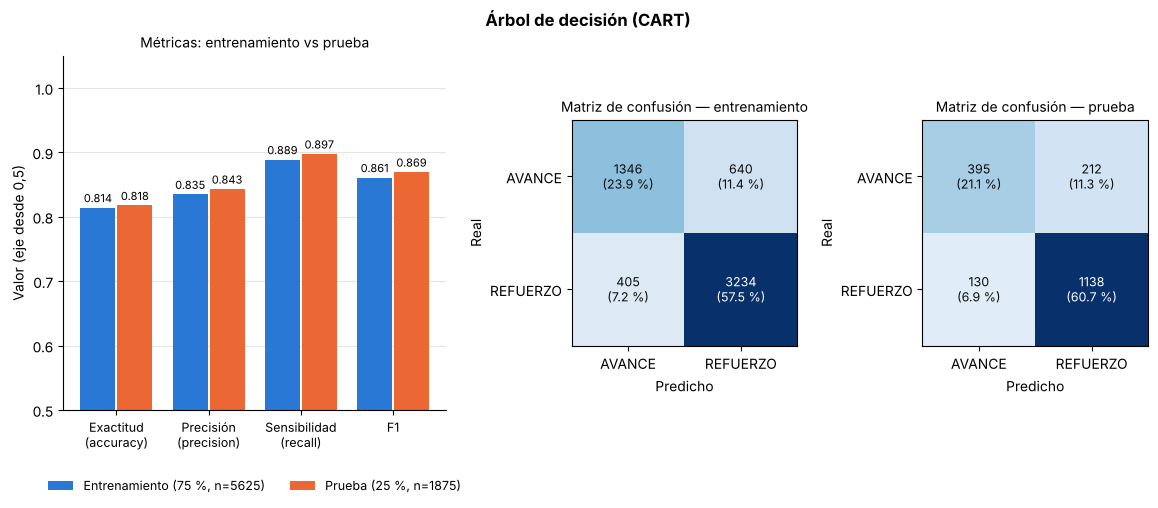


Importancia de variables: {'puntaje_tema': 0.8922, 'tiempo_promedio_seg': 0.046, 'puntaje_global': 0.0283, 'experiencia_previa_ninguna': 0.0181, 'aciertos_avanzado': 0.01, 'tema_ingenieria_social': 0.0053}
Resultados guardados en /tmp/claude-0/-home-user/05f6973f-df21-549c-aad8-950eca9b4e01/scratchpad/CyberMind-ML/pruebas/fase2_entreno_vs_prueba/resultados/01_arbol_decision.json


In [8]:
brecha = comparar(m_ent, m_pru)
graficar("01_arbol_decision", "Árbol de decisión (CART)", m_ent, m_pru, mostrar_figura=True)
nombres = list(modelo[0].get_feature_names_out())
importancias = sorted(zip(nombres, modelo[-1].feature_importances_), key=lambda t: -t[1])
extra = {"importancias": {n: round(float(v), 4) for n, v in importancias if v > 0},
         "reglas": export_text(modelo[-1], feature_names=nombres)}
print("\nImportancia de variables:", extra["importancias"])
guardar("01_arbol_decision", {"modelo": "Árbol de decisión (CART)", "datos": "cybermind_sintetico.csv",
                 "particion": "GroupShuffleSplit 75/25 por estudiante, random_state=0",
                 "hiperparametros": hiperparametros, "entrenamiento": m_ent, "prueba": m_pru,
                 "diferencia_entreno_menos_prueba": brecha, **extra})
resultados["Árbol de decisión (CART)"] = {"entrenamiento": m_ent, "prueba": m_pru}

## Modelo 2: Regresión logística

Regresión logística (salida = probabilidad de REFUERZO; se decide REFUERZO si p >= 0,5). Hiperparámetros fijados a mano (iguales al script original modelos/03_regresion_logistica.py): C=1.0, regularización L2, solver lbfgs, max_iter=1000. Numéricas estandarizadas, categóricas en one-hot.

*Equivale a `02_regresion_logistica.py`.*

### 2.1 Entrenar con el 75 %

In [9]:
modelo = Pipeline([
    ("prep", ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAS),
                                ("num", StandardScaler(), NUMERICAS)])),
    ("logit", LogisticRegression(C=1.0, max_iter=1000)),
])
modelo.fit(X_ent, y_ent)   # se entrena SOLO con el 75 % (el escalador también se ajusta solo con el 75 %)
hiperparametros = {"C": 1.0, "regularizacion": "L2", "solver": "lbfgs", "max_iter": 1000, "umbral_probabilidad": 0.5}

### 2.2 Evaluar con los datos de ENTRENAMIENTO (75 %)

In [10]:
pred_ent = modelo.predict(X_ent)
m_ent = metricas(y_ent, pred_ent)
mostrar("Regresión logística — ENTRENAMIENTO (75 %)", m_ent)


=== Regresión logística — ENTRENAMIENTO (75 %) — 5625 filas ===
  Exactitud (accuracy) ......... 0.8096
  Precisión REFUERZO ........... 0.8344
  Sensibilidad (recall) REFUERZO 0.8805
  F1 REFUERZO .................. 0.8568
  Matriz de confusión (filas = real, columnas = predicho):
                 pred AVANCE  pred REFUERZO
    real AVANCE        1350            636
    real REFUERZO       435           3204


### 2.3 Evaluar con los datos de PRUEBA (25 %)

In [11]:
pred_pru = modelo.predict(X_pru)
m_pru = metricas(y_pru, pred_pru)
mostrar("Regresión logística — PRUEBA (25 %)", m_pru)


=== Regresión logística — PRUEBA (25 %) — 1875 filas ===
  Exactitud (accuracy) ......... 0.8245
  Precisión REFUERZO ........... 0.8501
  Sensibilidad (recall) REFUERZO 0.8991
  F1 REFUERZO .................. 0.8739
  Matriz de confusión (filas = real, columnas = predicho):
                 pred AVANCE  pred REFUERZO
    real AVANCE         406            201
    real REFUERZO       128           1140


### 2.4 Comparación entrenamiento vs prueba y gráfica


=== Comparación entrenamiento vs prueba ===
  métrica               entreno   prueba  diferencia
  exactitud              0.8096   0.8245     -0.0149
  precision_REFUERZO     0.8344   0.8501     -0.0157
  recall_REFUERZO        0.8805   0.8991     -0.0186
  F1_REFUERZO            0.8568   0.8739     -0.0171



Gráfica guardada en /tmp/claude-0/-home-user/05f6973f-df21-549c-aad8-950eca9b4e01/scratchpad/CyberMind-ML/pruebas/fase2_entreno_vs_prueba/resultados/02_regresion_logistica.png


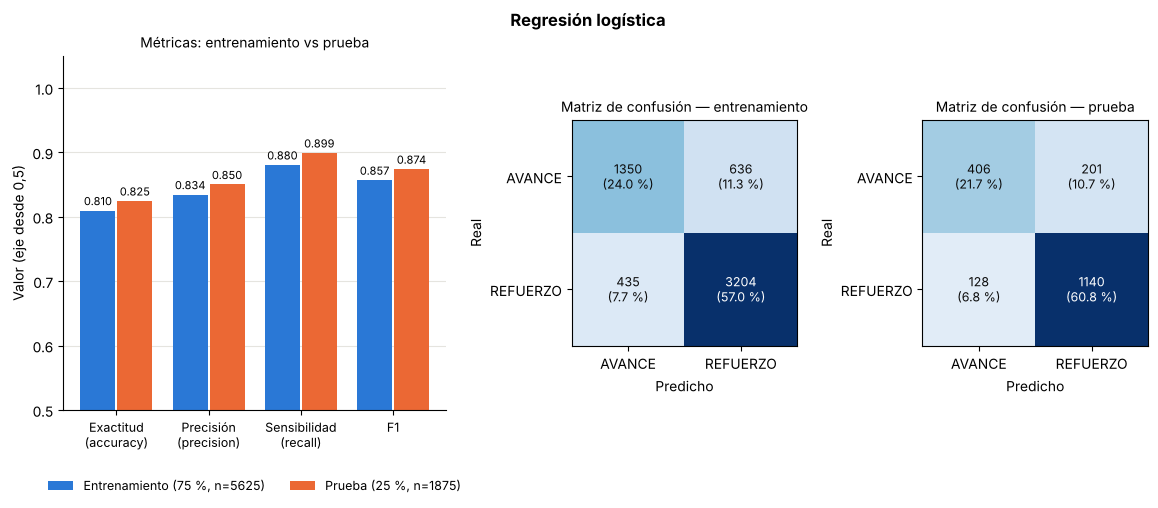


Coeficientes (positivo = empuja hacia REFUERZO): {'experiencia_previa_ninguna': 0.5529, 'aciertos_intermedio': -0.5448, 'tema_seguridad_web': 0.5202, 'tema_criptografia': 0.4947, 'tema_ingenieria_social': -0.479, 'tiempo_promedio_seg': 0.4601, 'puntaje_tema': -0.4278, 'aciertos_avanzado': -0.388, 'puntaje_global': -0.3418, 'tema_gestion_vulnerabilidades': 0.2561, 'tema_fundamentos_redes': -0.2497, 'experiencia_previa_laboral': -0.1066, 'experiencia_previa_cursos': 0.096, 'aciertos_basico': -0.02}
Resultados guardados en /tmp/claude-0/-home-user/05f6973f-df21-549c-aad8-950eca9b4e01/scratchpad/CyberMind-ML/pruebas/fase2_entreno_vs_prueba/resultados/02_regresion_logistica.json


In [12]:
brecha = comparar(m_ent, m_pru)
graficar("02_regresion_logistica", "Regresión logística", m_ent, m_pru, mostrar_figura=True)
nombres = [n.replace("num__", "").replace("cat__", "") for n in modelo[0].get_feature_names_out()]
coeficientes = sorted(zip(nombres, modelo[-1].coef_[0]), key=lambda t: -abs(t[1]))
extra = {"intercepto": round(float(modelo[-1].intercept_[0]), 4),
         "coeficientes_estandarizados": {n: round(float(c), 4) for n, c in coeficientes}}
print("\nCoeficientes (positivo = empuja hacia REFUERZO):", extra["coeficientes_estandarizados"])
guardar("02_regresion_logistica", {"modelo": "Regresión logística", "datos": "cybermind_sintetico.csv",
                 "particion": "GroupShuffleSplit 75/25 por estudiante, random_state=0",
                 "hiperparametros": hiperparametros, "entrenamiento": m_ent, "prueba": m_pru,
                 "diferencia_entreno_menos_prueba": brecha, **extra})
resultados["Regresión logística"] = {"entrenamiento": m_ent, "prueba": m_pru}

## Modelo 3: k vecinos más cercanos (kNN)

k vecinos más cercanos (kNN). Igual que en el script original modelos/04_knn.py, los hiperparámetros se buscan con validación cruzada agrupada (GroupKFold de 5) usando SOLO el 75 % de entrenamiento; el 25 % de prueba no participa en la búsqueda. Escalar las numéricas es obligatorio en kNN.

*Equivale a `03_knn.py`.*

### 3.1 Entrenar con el 75 %

In [13]:
REJILLA = {"knn__n_neighbors": [1, 3, 5, 9, 15, 25, 35, 51, 75, 101],
           "knn__weights": ["uniform", "distance"],
           "knn__p": [1, 2]}          # p=1 distancia Manhattan, p=2 euclídea
busqueda = GridSearchCV(
    Pipeline([("prep", ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAS),
                                          ("num", StandardScaler(), NUMERICAS)])),
              ("knn", KNeighborsClassifier())]),
    REJILLA, scoring="accuracy", cv=GroupKFold(n_splits=5), n_jobs=-1)
busqueda.fit(X_ent, y_ent, groups=g_ent)   # búsqueda + reentrenamiento final SOLO con el 75 %
modelo = busqueda.best_estimator_
hiperparametros = {k.replace("knn__", ""): v for k, v in busqueda.best_params_.items()}
print("Mejores hiperparámetros (CV en entrenamiento):", hiperparametros)

Mejores hiperparámetros (CV en entrenamiento): {'n_neighbors': 51, 'p': 1, 'weights': 'uniform'}


### 3.2 Evaluar con los datos de ENTRENAMIENTO (75 %)

In [14]:
pred_ent = modelo.predict(X_ent)
m_ent = metricas(y_ent, pred_ent)
mostrar("k vecinos más cercanos (kNN) — ENTRENAMIENTO (75 %)", m_ent)


=== k vecinos más cercanos (kNN) — ENTRENAMIENTO (75 %) — 5625 filas ===
  Exactitud (accuracy) ......... 0.8229
  Precisión REFUERZO ........... 0.8480
  Sensibilidad (recall) REFUERZO 0.8849
  F1 REFUERZO .................. 0.8661
  Matriz de confusión (filas = real, columnas = predicho):
                 pred AVANCE  pred REFUERZO
    real AVANCE        1409            577
    real REFUERZO       419           3220


### 3.3 Evaluar con los datos de PRUEBA (25 %)

In [15]:
pred_pru = modelo.predict(X_pru)
m_pru = metricas(y_pru, pred_pru)
mostrar("k vecinos más cercanos (kNN) — PRUEBA (25 %)", m_pru)


=== k vecinos más cercanos (kNN) — PRUEBA (25 %) — 1875 filas ===
  Exactitud (accuracy) ......... 0.8304
  Precisión REFUERZO ........... 0.8604
  Sensibilidad (recall) REFUERZO 0.8943
  F1 REFUERZO .................. 0.8770
  Matriz de confusión (filas = real, columnas = predicho):
                 pred AVANCE  pred REFUERZO
    real AVANCE         423            184
    real REFUERZO       134           1134


### 3.4 Comparación entrenamiento vs prueba y gráfica


=== Comparación entrenamiento vs prueba ===
  métrica               entreno   prueba  diferencia
  exactitud              0.8229   0.8304     -0.0075
  precision_REFUERZO     0.8480   0.8604     -0.0124
  recall_REFUERZO        0.8849   0.8943     -0.0094
  F1_REFUERZO            0.8661   0.8770     -0.0109



Gráfica guardada en /tmp/claude-0/-home-user/05f6973f-df21-549c-aad8-950eca9b4e01/scratchpad/CyberMind-ML/pruebas/fase2_entreno_vs_prueba/resultados/03_knn.png


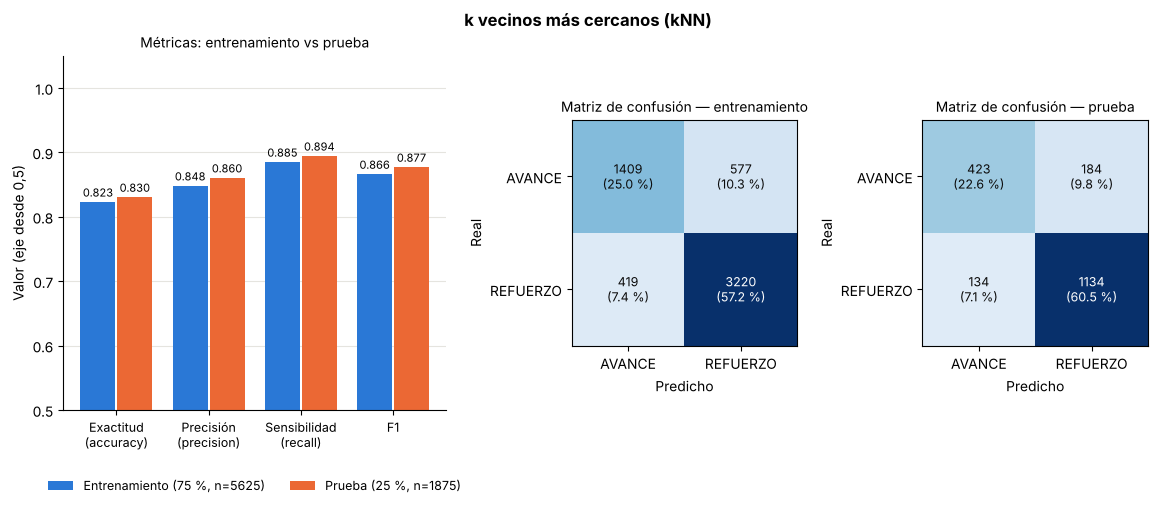


Exactitud media en validación cruzada (dentro del 75 %): 0.8169
Resultados guardados en /tmp/claude-0/-home-user/05f6973f-df21-549c-aad8-950eca9b4e01/scratchpad/CyberMind-ML/pruebas/fase2_entreno_vs_prueba/resultados/03_knn.json


In [16]:
brecha = comparar(m_ent, m_pru)
graficar("03_knn", "k vecinos más cercanos (kNN)", m_ent, m_pru, mostrar_figura=True)
extra = {"busqueda": "GridSearchCV, GroupKFold(5) sobre el 75 % de entrenamiento, métrica = exactitud",
         "combinaciones_probadas": len(busqueda.cv_results_["params"]),
         "exactitud_validacion_cruzada": round(float(busqueda.best_score_), 4)}
print(f"\nExactitud media en validación cruzada (dentro del 75 %): {extra['exactitud_validacion_cruzada']:.4f}")
guardar("03_knn", {"modelo": "k vecinos más cercanos (kNN)", "datos": "cybermind_sintetico.csv",
                 "particion": "GroupShuffleSplit 75/25 por estudiante, random_state=0",
                 "hiperparametros": hiperparametros, "entrenamiento": m_ent, "prueba": m_pru,
                 "diferencia_entreno_menos_prueba": brecha, **extra})
resultados["k vecinos más cercanos (kNN)"] = {"entrenamiento": m_ent, "prueba": m_pru}

## Modelo 4: Gradient Boosting de árboles (GBDT)

GBDT (Gradient Boosting de árboles de decisión). Se usa la variante "con búsqueda" del script original modelos/05_gbdt.py: rejilla de 48 combinaciones evaluada con GroupKFold de 5 usando SOLO el 75 % de entrenamiento. Categóricas en one-hot, numéricas sin escalar.

*Equivale a `04_gbdt.py`.*

### 4.1 Entrenar con el 75 %

In [17]:
REJILLA = {"gb__n_estimators": [50, 100, 200], "gb__learning_rate": [0.05, 0.1], "gb__max_depth": [2, 3],
           "gb__subsample": [0.8, 1.0], "gb__min_samples_leaf": [20, 50]}
busqueda = GridSearchCV(
    Pipeline([("prep", ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAS)],
                                         remainder="passthrough", verbose_feature_names_out=False)),
              ("gb", GradientBoostingClassifier(random_state=0))]),
    REJILLA, scoring="accuracy", cv=GroupKFold(n_splits=5), n_jobs=-1)
busqueda.fit(X_ent, y_ent, groups=g_ent)   # búsqueda + reentrenamiento final SOLO con el 75 %
modelo = busqueda.best_estimator_
hiperparametros = {k.replace("gb__", ""): v for k, v in busqueda.best_params_.items()}
print("Mejores hiperparámetros (CV en entrenamiento):", hiperparametros)

Mejores hiperparámetros (CV en entrenamiento): {'learning_rate': 0.05, 'max_depth': 3, 'min_samples_leaf': 20, 'n_estimators': 200, 'subsample': 0.8}


### 4.2 Evaluar con los datos de ENTRENAMIENTO (75 %)

In [18]:
pred_ent = modelo.predict(X_ent)
m_ent = metricas(y_ent, pred_ent)
mostrar("Gradient Boosting de árboles (GBDT) — ENTRENAMIENTO (75 %)", m_ent)


=== Gradient Boosting de árboles (GBDT) — ENTRENAMIENTO (75 %) — 5625 filas ===
  Exactitud (accuracy) ......... 0.8361
  Precisión REFUERZO ........... 0.8542
  Sensibilidad (recall) REFUERZO 0.9002
  F1 REFUERZO .................. 0.8766
  Matriz de confusión (filas = real, columnas = predicho):
                 pred AVANCE  pred REFUERZO
    real AVANCE        1427            559
    real REFUERZO       363           3276


### 4.3 Evaluar con los datos de PRUEBA (25 %)

In [19]:
pred_pru = modelo.predict(X_pru)
m_pru = metricas(y_pru, pred_pru)
mostrar("Gradient Boosting de árboles (GBDT) — PRUEBA (25 %)", m_pru)


=== Gradient Boosting de árboles (GBDT) — PRUEBA (25 %) — 1875 filas ===
  Exactitud (accuracy) ......... 0.8304
  Precisión REFUERZO ........... 0.8561
  Sensibilidad (recall) REFUERZO 0.9006
  F1 REFUERZO .................. 0.8778
  Matriz de confusión (filas = real, columnas = predicho):
                 pred AVANCE  pred REFUERZO
    real AVANCE         415            192
    real REFUERZO       126           1142


### 4.4 Comparación entrenamiento vs prueba y gráfica


=== Comparación entrenamiento vs prueba ===
  métrica               entreno   prueba  diferencia
  exactitud              0.8361   0.8304     +0.0057
  precision_REFUERZO     0.8542   0.8561     -0.0019
  recall_REFUERZO        0.9002   0.9006     -0.0004
  F1_REFUERZO            0.8766   0.8778     -0.0012



Gráfica guardada en /tmp/claude-0/-home-user/05f6973f-df21-549c-aad8-950eca9b4e01/scratchpad/CyberMind-ML/pruebas/fase2_entreno_vs_prueba/resultados/04_gbdt.png


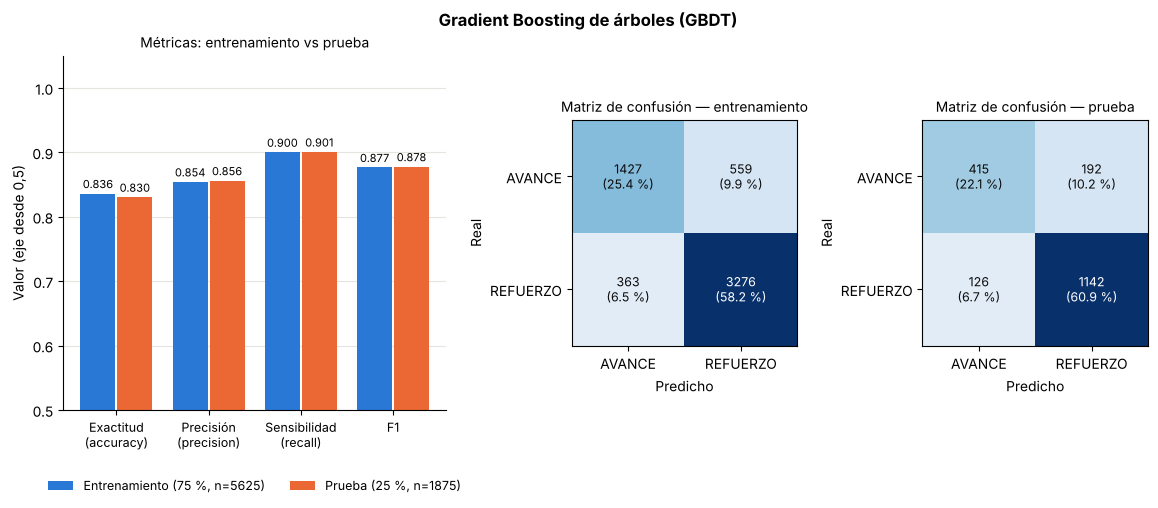


Exactitud media en validación cruzada (dentro del 75 %): 0.8194
Importancia de variables: {'puntaje_tema': 0.7312, 'tiempo_promedio_seg': 0.0876, 'puntaje_global': 0.0741, 'aciertos_intermedio': 0.0311, 'tema_ingenieria_social': 0.0173, 'experiencia_previa_ninguna': 0.0162, 'aciertos_basico': 0.0143, 'tema_fundamentos_redes': 0.0087, 'tema_criptografia': 0.0064, 'tema_seguridad_web': 0.0057}
Resultados guardados en /tmp/claude-0/-home-user/05f6973f-df21-549c-aad8-950eca9b4e01/scratchpad/CyberMind-ML/pruebas/fase2_entreno_vs_prueba/resultados/04_gbdt.json


In [20]:
brecha = comparar(m_ent, m_pru)
graficar("04_gbdt", "Gradient Boosting de árboles (GBDT)", m_ent, m_pru, mostrar_figura=True)
nombres = list(modelo[0].get_feature_names_out())
importancias = sorted(zip(nombres, modelo[-1].feature_importances_), key=lambda t: -t[1])
extra = {"busqueda": "GridSearchCV, GroupKFold(5) sobre el 75 % de entrenamiento, métrica = exactitud",
         "combinaciones_probadas": len(busqueda.cv_results_["params"]),
         "exactitud_validacion_cruzada": round(float(busqueda.best_score_), 4),
         "importancias": {n: round(float(v), 4) for n, v in importancias if v > 0.005}}
print(f"\nExactitud media en validación cruzada (dentro del 75 %): {extra['exactitud_validacion_cruzada']:.4f}")
print("Importancia de variables:", extra["importancias"])
guardar("04_gbdt", {"modelo": "Gradient Boosting de árboles (GBDT)", "datos": "cybermind_sintetico.csv",
                 "particion": "GroupShuffleSplit 75/25 por estudiante, random_state=0",
                 "hiperparametros": hiperparametros, "entrenamiento": m_ent, "prueba": m_pru,
                 "diferencia_entreno_menos_prueba": brecha, **extra})
resultados["Gradient Boosting de árboles (GBDT)"] = {"entrenamiento": m_ent, "prueba": m_pru}

## 5. Comparación de los 4 modelos

Tabla y gráficas con la exactitud de cada modelo en entrenamiento y en prueba, y la diferencia entre ambas.

In [21]:
tabla = pd.DataFrame({
    modelo: {"exactitud_entreno": r["entrenamiento"]["exactitud"], "exactitud_prueba": r["prueba"]["exactitud"],
             "diferencia": round(r["entrenamiento"]["exactitud"] - r["prueba"]["exactitud"], 4),
             "precision_prueba": r["prueba"]["precision_REFUERZO"], "recall_prueba": r["prueba"]["recall_REFUERZO"],
             "F1_entreno": r["entrenamiento"]["F1_REFUERZO"], "F1_prueba": r["prueba"]["F1_REFUERZO"]}
    for modelo, r in resultados.items()}).T
base = y_pru.mean()   # exactitud de responder siempre REFUERZO en prueba (referencia mínima)
print(f"Referencia: decir siempre REFUERZO acierta {base:.4f} en prueba")
tabla.to_csv(SALIDA / "comparacion_4_modelos.csv")
tabla

Referencia: decir siempre REFUERZO acierta 0.6763 en prueba


,exactitud_entreno,exactitud_prueba,diferencia,precision_prueba,recall_prueba,F1_entreno,F1_prueba
Árbol de decisión (CART),0.8142,0.8176,-0.0034,0.8430,0.8975,0.8609,0.8694
Regresión logística,0.8096,0.8245,-0.0149,0.8501,0.8991,0.8568,0.8739
k vecinos más cercanos (kNN),0.8229,0.8304,-0.0075,0.8604,0.8943,0.8661,0.8770
Gradient Boosting de árboles (GBDT),0.8361,0.8304,0.0057,0.8561,0.9006,0.8766,0.8778


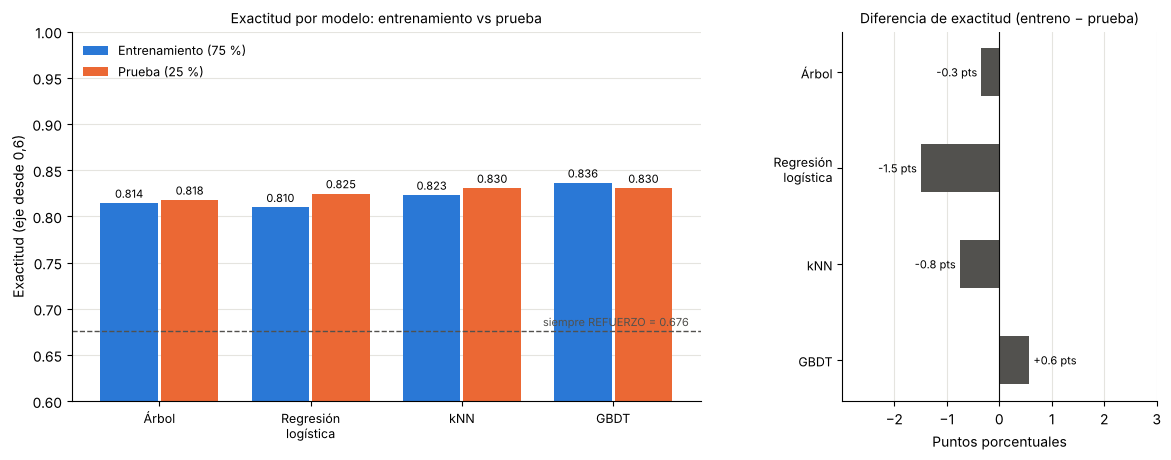

In [22]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [2, 1], "wspace": 0.3})
nombres = list(resultados)
cortos = ["Árbol", "Regresión\nlogística", "kNN", "GBDT"]
x = np.arange(len(nombres))
w = 0.38
b1 = ax1.bar(x - w / 2 - 0.01, tabla["exactitud_entreno"], w, color=COLOR_ENT, label="Entrenamiento (75 %)")
b2 = ax1.bar(x + w / 2 + 0.01, tabla["exactitud_prueba"], w, color=COLOR_PRU, label="Prueba (25 %)")
ax1.bar_label(b1, fmt="%.3f", fontsize=8, padding=2)
ax1.bar_label(b2, fmt="%.3f", fontsize=8, padding=2)
ax1.axhline(base, color="#52514e", linestyle="--", linewidth=1)
ax1.text(len(nombres) - 0.5, base + 0.005, f"siempre REFUERZO = {base:.3f}", ha="right", fontsize=8, color="#52514e")
ax1.set_xticks(x, cortos, fontsize=9)
ax1.set_ylim(0.6, 1.0)
ax1.set_ylabel("Exactitud (eje desde 0,6)")
ax1.set_title("Exactitud por modelo: entrenamiento vs prueba", fontsize=10)
ax1.legend(loc="upper left", frameon=False, fontsize=9)
dif = tabla["diferencia"] * 100
b3 = ax2.barh(x, dif, color="#52514e", height=0.5)
ax2.bar_label(b3, fmt="%+.1f pts", fontsize=8, padding=3)
ax2.axvline(0, color="#0b0b0b", linewidth=0.8)
ax2.set_yticks(x, cortos, fontsize=9)
ax2.invert_yaxis()
ax2.set_xlim(min(-2.5, dif.min() - 1.5), max(3, dif.max() + 2))
ax2.set_xlabel("Puntos porcentuales")
ax2.set_title("Diferencia de exactitud (entreno − prueba)", fontsize=10)
for ax in (ax1, ax2):
    ax.grid(axis="y" if ax is ax1 else "x", color="#e5e4df", linewidth=0.8)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
fig.savefig(SALIDA / "comparacion_4_modelos.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Lectura de resultados

Las cifras de esta sección se escribieron con la ejecución guardada en este notebook (semilla fija, así que deben repetirse igual).

- **Ningún modelo muestra sobreajuste.** En los 4 modelos la exactitud de entrenamiento y la de prueba quedan a menos de 1,5 puntos: árbol 0,814 → 0,818; regresión logística 0,810 → 0,825; kNN 0,823 → 0,830; GBDT 0,836 → 0,830. Si un modelo estuviera memorizando, entrenamiento estaría muy por encima de prueba (por ejemplo, kNN con k = 1 da 1,000 en entrenamiento); aquí no pasa.
- **Prueba sale un poco más alta que entrenamiento en 3 de los 4 modelos.** No es un error: con una sola partición, los 375 estudiantes de prueba resultan algo más fáciles de clasificar que los 1 125 de entrenamiento. La validación cruzada dentro del 75 % (kNN 0,817; GBDT 0,819) cae en el mismo rango, lo que confirma que las diferencias son ruido de muestreo. Con 1 875 filas de prueba, el margen de error de la exactitud ronda ±1,8 puntos.
- **Los 4 modelos rinden casi igual en prueba** (de 0,818 a 0,830, 1,2 puntos de diferencia, dentro del margen de error). Todos superan con claridad la referencia de responder siempre REFUERZO (≈ 0,676). Con estos datos la elección entre modelos no se puede decidir solo por exactitud; pesan también la interpretabilidad y la simplicidad.
- **Por qué ninguno pasa de ~0,83:** la etiqueta del dataset tiene un 5 % de ruido intencional y 9 preguntas por tema miden el dominio con error, así que hay un techo que ningún modelo puede superar con estas variables.
- **Variable más usada:** en los modelos de árboles, `puntaje_tema` concentra la mayor importancia (0,89 en el árbol, 0,73 en GBDT), seguida de `tiempo_promedio_seg` y `puntaje_global`. Esto sirve como insumo para la justificación de variables que pidió el profesor.

**Nota del equipo:** al equipo (David, Nicolás y Perrochueco67) le gusta la regresión logística. Este notebook no toma preferencia por ningún modelo; la elección queda pendiente del consejo del profesor.